# 03 - Matrix Operations

This notebook demonstrates matrix arithmetic and linear algebra through `quantum_space_agi.scientific.matrix`.

For compatible matrices, multiplication is
$$(AB)_{ij}=\sum_k A_{ik}B_{kj}.$$

A square matrix inverse satisfies $A^{-1}A \approx I$ in finite precision. The package also checks numerical rank, rejects singular matrices, and can reject systems above a configurable condition-number limit.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
repo_root = next((p for p in (cwd, *cwd.parents) if (p / "src").is_dir()), cwd)
sys.path.insert(0, str(repo_root / "src"))

import numpy as np
import matplotlib.pyplot as plt
from quantum_space_agi.scientific import matrix
from quantum_space_agi.scientific.errors import ScientificError


## Arithmetic and shape validation

Addition and subtraction require identical shapes. Multiplication requires the inner dimensions to match.

In [2]:
left = [[1, 2, 3], [4, 5, 6]]
right = [[7, 8], [9, 10], [11, 12]]

print("product:")
print(matrix.multiply(left, right))
print("transpose:")
print(matrix.transpose(left))

try:
    matrix.add([[1, 2]], [[1], [2]])
except ScientificError as exc:
    print("expected shape error:", exc.code.value)


product:
[[ 58.  64.]
 [139. 154.]]
transpose:
[[1. 4.]
 [2. 5.]
 [3. 6.]]
expected shape error: invalid_shape


**Expected product:**

`[[58, 64], [139, 154]]`

**Transpose:**

`[[1, 4], [2, 5], [3, 6]]`

**Expected validation:** shape mismatch should produce `invalid_shape`.

In [3]:
product = matrix.multiply(left, right)
np.testing.assert_array_equal(product, [[58, 64], [139, 154]])
np.testing.assert_array_equal(matrix.transpose(left), [[1, 4], [2, 5], [3, 6]])
print("Matrix shape and arithmetic validations passed.")


Matrix shape and arithmetic validations passed.


## Determinant, inverse, and linear solve

A linear system $Ax=b$ is solved directly with NumPy after the package validates the matrix dimensions, finite values, rank, and condition number.

In [4]:
a = [[4, 7], [2, 6]]
b = [2, 12]

print("determinant:", matrix.determinant(a))
print("inverse:")
print(matrix.inverse(a))
print("solution:", matrix.solve(a, b))

solution = matrix.solve(a, b)
print("residual:", matrix.multiply(a, solution.reshape(2, 1)).reshape(-1) - np.array(b))


determinant: 10.000000000000002
inverse:
[[ 0.6 -0.7]
 [-0.2  0.4]]
solution: [-7.2  4.4]
residual: [0. 0.]


**Expected determinant:** `10`. For this matrix, the inverse is approximately `[[0.6, -0.7], [-0.2, 0.4]]` and the solution is approximately `[-7.2, 4.4]`.

In [5]:
expected_inverse = np.array([[0.6, -0.7], [-0.2, 0.4]])
np.testing.assert_allclose(matrix.inverse(a), expected_inverse, atol=1e-12, rtol=1e-9)

solution = matrix.solve(a, b)
np.testing.assert_allclose(
    matrix.multiply(a, solution.reshape(2, 1)).reshape(-1),
    b,
    atol=1e-12,
    rtol=1e-9,
)
print("Inverse and solution residual passed.")


Inverse and solution residual passed.


## Visualization: transformation of a unit square

A matrix maps the unit square into a parallelogram. This provides intuition for determinant magnitude as area scaling.

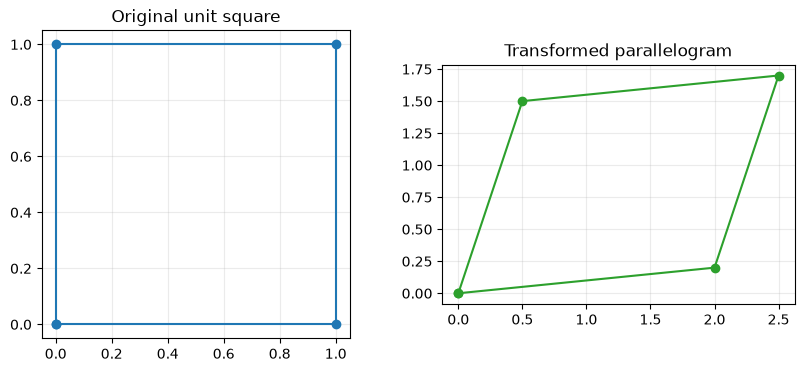

determinant: 2.9
visual area scaling: 2.9


In [6]:
transform = np.array([[2.0, 0.5], [0.2, 1.5]])
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])
mapped = square @ transform.T

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(square[:, 0], square[:, 1], marker="o")
axes[0].set_title("Original unit square")
axes[1].plot(mapped[:, 0], mapped[:, 1], marker="o", color="C2")
axes[1].set_title("Transformed parallelogram")
for ax in axes:
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.25)
plt.show()

print("determinant:", matrix.determinant(transform))
print("visual area scaling:", abs(np.linalg.det(transform)))


## Numerical limitations and validation

- Matrices must be non-empty, rectangular, real, and finite.
- The default condition-number limit for inverse and solve is `1e12`.
- Singular or rank-deficient matrices raise `singular_matrix`.
- Ill-conditioned matrices raise `uncertain_result` rather than silently returning a poor solution.
- Determinants and matrix products can overflow or underflow even when inputs are finite.
- Identity residuals are expected to be approximate, not exact, due to Float64 rounding.